# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SanniyaAslam/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [ ]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
REPO_DIR = "/content/flyrank-ml-internship"
if IN_COLAB and not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/SanniyaAslam/flyrank-ml-internship.git", REPO_DIR], check=True)
os.chdir(REPO_DIR)
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "duckdb", "huggingface_hub", "scikit-learn", "matplotlib"], check=True)

from google.colab import userdata
HF_TOKEN = userdata.get("HF_TOKEN")

import duckdb, json, pandas as pd, numpy as np
con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")
REL = "hf://datasets/FlyRank/internship-warehouse"

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

df = con.sql(f"""
    WITH first_half AS (
        SELECT client_hash_id, content_hash_id,
               SUM(gsc_impressions) AS impressions_fh,
               SUM(gsc_clicks) AS clicks_fh,
               AVG(gsc_avg_position) AS avg_position_fh
        FROM read_parquet('{REL}/fact_content_daily_performance/month=2026-03/*.parquet')
        WHERE gsc_data_available IS TRUE AND EXTRACT(day FROM report_date) <= 15
        GROUP BY client_hash_id, content_hash_id
    ),
    second_half AS (
        SELECT client_hash_id, content_hash_id, SUM(gsc_clicks) AS clicks_sh
        FROM read_parquet('{REL}/fact_content_daily_performance/month=2026-03/*.parquet')
        WHERE gsc_data_available IS TRUE AND EXTRACT(day FROM report_date) > 15
        GROUP BY client_hash_id, content_hash_id
    )
    SELECT fh.client_hash_id, fh.content_hash_id,
           fh.impressions_fh, fh.clicks_fh, fh.avg_position_fh,
           sh.clicks_sh, d.word_count,
           DATE_DIFF('day', d.content_updated_date, DATE '2026-03-15') AS days_since_update_fh
    FROM first_half fh
    JOIN second_half sh ON fh.client_hash_id = sh.client_hash_id AND fh.content_hash_id = sh.content_hash_id
    JOIN read_parquet('{REL}/dim_content.parquet') d
      ON fh.client_hash_id = d.client_hash_id AND fh.content_hash_id = d.content_hash_id
    WHERE fh.impressions_fh > 0
    ORDER BY fh.client_hash_id, fh.content_hash_id
""").df()

df["ctr_fh"] = df["clicks_fh"] / df["impressions_fh"]
df["is_declining"] = (df["clicks_sh"] < df["clicks_fh"]).astype(int)
df["word_count"] = df["word_count"].fillna(df["word_count"].median())
df["days_since_update_fh"] = df["days_since_update_fh"].clip(lower=0)

features = ["impressions_fh", "ctr_fh", "avg_position_fh", "days_since_update_fh", "word_count"]
X = df[features].replace([np.inf, -np.inf], np.nan).fillna(0)
y = df["is_declining"].values
groups = df["client_hash_id"].values

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
df_test = df.iloc[test_idx].reset_index(drop=True)

def precision_at_k(scores, labels, k):
    order = np.argsort(-np.asarray(scores))
    return np.asarray(labels)[order[:k]].mean()

print("Rows:", len(df), "| Train:", len(train_idx), "| Test:", len(test_idx))
print("Declining rate:", round(df["is_declining"].mean(), 3))
print("Client overlap train/test:", len(set(groups[train_idx]) & set(groups[test_idx])))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 141467 | Train: 129917 | Test: 11550
Declining rate: 0.203
Client overlap train/test: 0


## 1. Question

*The research question and the decision it supports.*Research question: can observable, pre-decision search signals (impressions, click-through rate, average position, days since last update and word count) rank pages that go on to lose clicks better than a hand-written rule?

Decision supported: which pages a content or SEO reviewer should open first, given limited review capacity. Lane 2: refresh and content opportunity scoring.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*Release: FlyRank internship warehouse (pseudonymized, v20260703). All client, content, keyword and URL identifiers are hashes.

Tables: daily performance fact table (partition month=2026-03), content dimension, client dimension.

Window: March 2026. Days 1-15 give the features, days 16-31 give only the label. The final warehouse month was never used.

Kept: rows with Search Console data available (checked with IS TRUE) and impressions in the first half.

Excluded: the product's own decision fields (last optimized date, optimization eligible date), because they record a decision already made and would leak the outcome.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*Label: a page is "declining" if its clicks in days 16-31 are lower than in days 1-15. A short-window proxy, not long-term content health.

Features (all first-half only, suffix _fh): impressions, click-through rate, average position, days since update (negative values clipped to zero), word count.

Baseline: flag a page if it has gone 180+ days without an update, has 100+ impressions and a click-through rate below 2%; rank flagged pages by impressions times staleness.

Models: logistic regression (readable) and random forest (200 trees, depth 6, balanced classes).

Validation: client-grouped split, 25% of clients held out, zero client overlap (verified in the setup cell). Metric: Precision@50, because a reviewer reads a short list.

Leakage checks: no feature correlates above 0.21 with the label; no feature uses second-half clicks. A Week 6 test showed a random row split shared 41 clients across train and test and gave a higher ROC AUC (0.928 vs 0.907), which is why the grouped split is the one reported.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [ ]:
test_slice = df_test
baseline_flag = ((test_slice["days_since_update_fh"] >= 180) &
                 (test_slice["impressions_fh"] >= 100) &
                 (test_slice["ctr_fh"] < 0.02)).astype(int)
baseline_score = baseline_flag * test_slice["impressions_fh"] * test_slice["days_since_update_fh"]
baseline_p50 = precision_at_k(baseline_score, y_test, 50)

logreg = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train, y_train)
lr_scores = logreg.predict_proba(X_test)[:, 1]
lr_p50, lr_auc = precision_at_k(lr_scores, y_test, 50), roc_auc_score(y_test, lr_scores)

rf = RandomForestClassifier(n_estimators=200, max_depth=6, class_weight="balanced", random_state=42).fit(X_train, y_train)
rf_scores = rf.predict_proba(X_test)[:, 1]
rf_p50, rf_auc = precision_at_k(rf_scores, y_test, 50), roc_auc_score(y_test, rf_scores)

results = pd.DataFrame({
    "method": ["Hand-written rule", "Logistic regression", "Random forest"],
    "precision_at_50": [baseline_p50, lr_p50, rf_p50],
    "roc_auc": [np.nan, lr_auc, rf_auc],
}).round(3)
display(results)

print(f"On this client-held-out split the rule reached Precision@50 = {baseline_p50:.2f}, "
      f"logistic regression {lr_p50:.2f} and random forest {rf_p50:.2f} (ROC AUC {rf_auc:.3f}).")

coef_table = pd.DataFrame({"feature": features,
                           "logreg_coefficient": logreg.coef_[0],
                           "rf_importance": rf.feature_importances_}).round(3)
display(coef_table.sort_values("rf_importance", ascending=False))

,method,precision_at_50,roc_auc
0,Hand-written rule,0.32,NaN
1,Logistic regression,0.78,0.875
2,Random forest,0.88,0.908


On this client-held-out split the rule reached Precision@50 = 0.32, logistic regression 0.78 and random forest 0.88 (ROC AUC 0.908).


,feature,logreg_coefficient,rf_importance
1,ctr_fh,74.705,0.820
0,impressions_fh,0.000,0.154
2,avg_position_fh,-0.026,0.020
4,word_count,0.000,0.005
3,days_since_update_fh,-0.003,0.001


Both learned models ranked above the rule on the same held-out pages. The rule's own Precision@50 depends on which clients are held out (0.20 in earlier runs, 0.32 in this run), so the gap should not be read as a fixed multiple. The random forest's ROC AUC was steady at about 0.91; its Precision@50 was 0.88 here and 0.74 in one earlier run whose query had no fixed row order.

The random forest put about 82% of its importance on first-half click-through rate. Because that feature is built from the same first-half clicks the label compares against, part of the signal is likely mechanical, not evidence of a real decline pattern. The random forest is only modestly better than the logistic regression.

## 5. Limitations

*What this work cannot claim.*This work does not show that refreshing a page causes recovery, and it says nothing about how Google ranks pages. It covers one month (March 2026) and an unbalanced panel of clients, so it may not hold in other months or for new clients.

The label is partly mechanical: it compares clicks in two halves while a feature uses first-half clicks, and a page with no first-half clicks cannot be labelled declining. Some of the model's skill may be regression toward the mean.

Pages with very few impressions are fragile, because one click changes the label. Some update dates fall after the reference date, giving negative staleness; these were clipped to zero, not repaired.

This is observational decision-support work, not a production model.The final random forest relied mostly on first-half click-through rate, which is consistent with the label being partly mechanical.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*In the Week 7 playbook run, 11,550 held-out pages produced 4,830 "investigate", 19 "monitor" and 6,701 "no action" pages. No page reached the stale-specific "refresh now" tier. The highest-scored pages were recently updated, low-volume pages (about 15 to 19 half-month impressions), so staleness did not drive the top of the queue.

Ranked recommendations:
1. Put a minimum-volume floor in front of the queue (for example 100 impressions in the window). This is suggested by the error analysis and has not yet been tested.
2. Review the "investigate" tier by traffic at stake as well as by score.
3. Check outside explanations first: seasonality, a competitor's new page, search-result layout changes, tracking problems.
4. Treat any refresh as a test: compare with comparable untouched pages at 30 and 60 days.
5. Revalidate if the declining rate drifts well from about 20%, if Precision@50 on a fresh month drops below the range seen here, if a very different client is added, or after three months.

Never automate: publishing, unpublishing or deleting pages from the score; editing content without a person reviewing that page; presenting the score as a Google ranking prediction; promising a client that a refresh will recover traffic.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

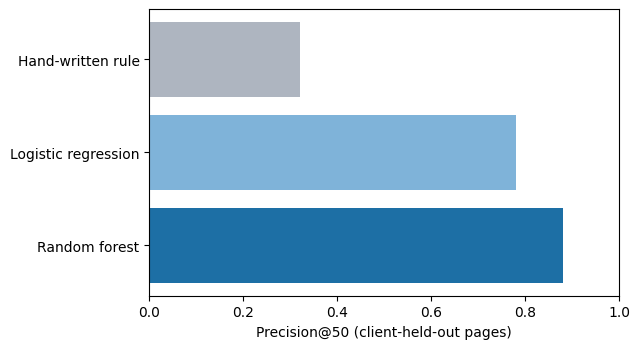

Saved work/figures/model_vs_baseline.png and work/outputs/capstone_metrics.json


In [ ]:
import matplotlib.pyplot as plt
os.makedirs("work/figures", exist_ok=True)
os.makedirs("work/outputs", exist_ok=True)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(results["method"], results["precision_at_50"], color=["#aeb5c0", "#7fb3d9", "#1d6fa5"])
ax.set_xlim(0, 1)
ax.set_xlabel("Precision@50 (client-held-out pages)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("work/figures/model_vs_baseline.png", dpi=150)
plt.show()

metrics = {
    "split": "client-grouped (GroupShuffleSplit, test_size=0.25, random_state=42)",
    "rows": int(len(df)), "test_rows": int(len(df_test)),
    "declining_rate": float(df["is_declining"].mean()),
    "results": results.to_dict(orient="records"),
}
with open("work/outputs/capstone_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("Saved work/figures/model_vs_baseline.png and work/outputs/capstone_metrics.json")

## 5-minute demo outline
1. (30 sec) Question: can signals known before a reviewer opens a page predict which pages will lose clicks, better than a one-line rule?
2. (1 min) Method: one month of FlyRank's pseudonymized search data, features from days 1-15, label from days 16-31, client-grouped validation so no client appears in both train and test.
3. (1 min) Chart: the Precision@50 bar chart (rule 0.32, logistic regression 0.78, random forest 0.88).
4. (1.5 min) One honest result: the models ranked above the rule, but most of the forest's weight sat on first-half click-through rate, which is partly mechanical, and the top-ranked pages were tiny-volume pages. So this is decision support, not proof.
5. (1 min) One recommendation: put a minimum-volume floor in front of the review queue and have a person check for outside causes before refreshing anything.

## Social post
Most "AI for SEO" claims skip the boring part: validation. On FlyRank's pseudonymized search data I built features from the first half of a month, defined the label from the second half, and held out whole clients so none appeared in both train and test. The models beat a hand-written rule, but my own audit showed most of the signal came from one partly mechanical feature, so I report it as decision support, not proof. Paper: https://sanniyaaslam.github.io/flyrank-ml-internship/ Code: https://github.com/SanniyaAslam/flyrank-ml-internship

Built and validated a content-prioritisation model on a one-month slice of a 79M-row pseudonymized search warehouse, beating a rule-based baseline under a client-grouped, leakage-audited validation design. Turned the model output into a human-reviewed action playbook with explicit limits, no-go rules and retraining triggers. Published the full method, validation audit and reproducible code as a deployed research paper and public GitHub repository.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
